In [2]:
import xarray as xr

file_path = "biomass_inputs/stack_02/L1C/BIO_S1_STA__1S_20260927T214341_20260927T214402_T_G01_M05_C05_T028_F217_02_DZ1R14/annotation_coregistered/bio_s1_sta__1s_20260927t214341_20260927t214402_t_g01_m05_c05_t028_f217_lut.nc"

ds = xr.open_dataset(file_path)
print(list(ds.data_vars))
print(list(ds.coords))
print(ds)

[]
['relativeAzimuthTime', 'slantRangeTime']
<xarray.Dataset> Size: 18kB
Dimensions:              (relativeAzimuthTime: 1735, slantRangeTime: 466)
Coordinates:
  * relativeAzimuthTime  (relativeAzimuthTime) float64 14kB 0.0 ... 20.42
  * slantRangeTime       (slantRangeTime) float64 4kB 0.004974 ... 0.005097
Data variables:
    *empty*
Attributes: (12/21)
    mission:               BIOMASS
    swath:                 S1
    productType:           STA
    polarisationList:      ['H/H', 'H/V', 'V/H', 'V/V']
    startTime:             2026-09-27T21:43:41.955342
    stopTime:              2026-09-27T21:44:02.390168
    ...                    ...
    orbitPass:             Descending
    platformHeading:       -132.4862477982106
    dataTakeID:            62066620
    frame:                 217
    productComposition:    Nominal
    noDataValue:           -9999.0


In [8]:
import netCDF4 as nc

def list_arrays(group, prefix=""):
    for name, var in group.variables.items():
        print(f"{prefix}{name}: shape={var.shape}, dtype={var.dtype}")
    for gname, sub in group.groups.items():
        list_arrays(sub, prefix=f"{prefix}{gname}/")

with nc.Dataset(file_path, "r") as ds:
    list_arrays(ds)

relativeAzimuthTime: shape=(1735,), dtype=float64
slantRangeTime: shape=(466,), dtype=float64
radiometry/sigmaNought: shape=(1735, 466), dtype=float32
radiometry/gammaNought: shape=(1735, 466), dtype=float32
denoising/denoisingHH: shape=(1735, 466), dtype=float32
denoising/denoisingHV: shape=(1735, 466), dtype=float32
denoising/denoisingVH: shape=(1735, 466), dtype=float32
denoising/denoisingVV: shape=(1735, 466), dtype=float32
geometry/latitude: shape=(1735, 466), dtype=float64
geometry/longitude: shape=(1735, 466), dtype=float64
geometry/height: shape=(1735, 466), dtype=float64
geometry/incidenceAngle: shape=(1735, 466), dtype=float32
geometry/elevationAngle: shape=(1735, 466), dtype=float32
geometry/azimuthTerrainSlope: shape=(1735, 466), dtype=float32
geometry/rangeTerrainSlope: shape=(1735, 466), dtype=float32
coregistration/azimuthCoregistrationShifts: shape=(1735, 466), dtype=float32
coregistration/azimuthOrbitCoregistrationShifts: shape=(1735, 466), dtype=float32
coregistration

In [10]:
ds.groups.items()

RuntimeError: NetCDF: Not a valid ID

In [11]:
ds["azimuthCoregistrationShifts"]

IndexError: azimuthCoregistrationShifts not found in /

In [16]:
ds = xr.open_dataset(file_path, group="coregistration")
arr1 = ds["azimuthCoregistrationShifts"].values
print(arr1)

ds = xr.open_dataset(file_path, group="coregistration")
arr2 = ds["azimuthOrbitCoregistrationShifts"].values

az_shift = arr1 - arr2

ds = xr.open_dataset(file_path, group="coregistration")
arr3 = ds["rangeCoregistrationShifts"].values
print(arr3)

ds = xr.open_dataset(file_path, group="coregistration")
arr4 = ds["rangeOrbitCoregistrationShifts"].values
print(arr4)

ran_shift = arr3-arr4




# coregistration/azimuthCoregistrationShifts: shape=(1735, 466), dtype=float32
# coregistration/azimuthOrbitCoregistrationShifts: shape=(1735, 466), dtype=float32
# coregistration/rangeCoregistrationShifts: shape=(1735, 466), dtype=float32
# coregistration/rangeOrbitCoregistrationShifts: shape=(1735, 466), dtype=float32

[[nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 ...
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]]
[[nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 ...
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]]
[[nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 ...
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]]


az: (1735, 466) -1.6031036 3.070961
ran: (1735, 466) 0.56010437 2.5393372


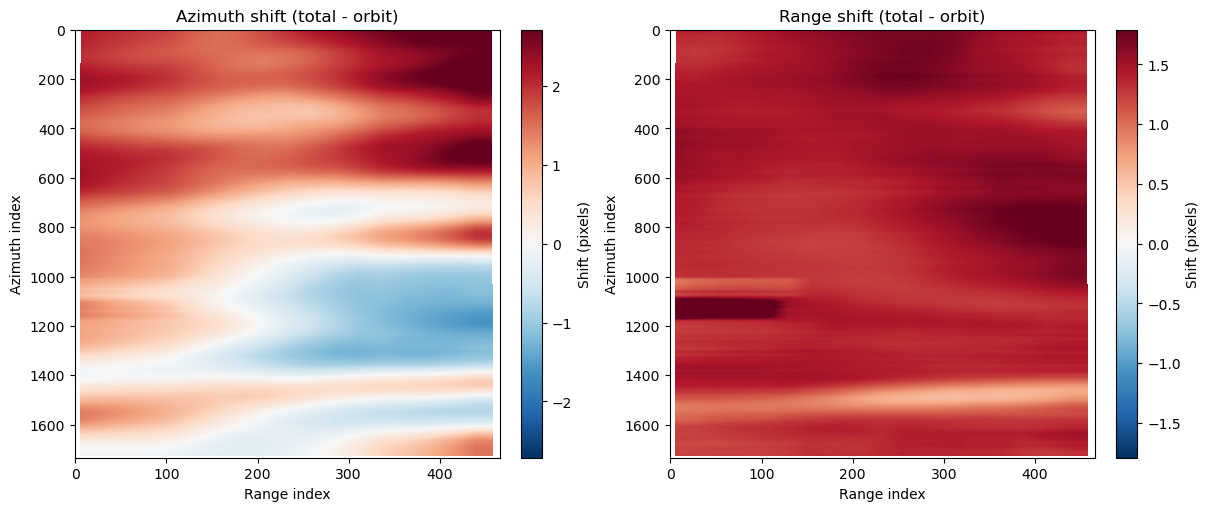

In [17]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

ds = xr.open_dataset(file_path, group="coregistration")

az_shift = ds["azimuthCoregistrationShifts"].values - ds["azimuthOrbitCoregistrationShifts"].values
ran_shift = ds["rangeCoregistrationShifts"].values - ds["rangeOrbitCoregistrationShifts"].values

print("az:", az_shift.shape, np.nanmin(az_shift), np.nanmax(az_shift))
print("ran:", ran_shift.shape, np.nanmin(ran_shift), np.nanmax(ran_shift))

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

for ax, data, title in zip(
    axes,
    [az_shift, ran_shift],
    ["Azimuth shift (total - orbit)", "Range shift (total - orbit)"],
):
    # symmetric colour limits centred on zero, robust to outliers
    vmax = np.nanpercentile(np.abs(data), 98)
    im = ax.imshow(data, cmap="RdBu_r", vmin=-vmax, vmax=vmax, origin="upper", aspect="auto")
    ax.set_title(title)
    ax.set_xlabel("Range index")
    ax.set_ylabel("Azimuth index")
    fig.colorbar(im, ax=ax, label="Shift (pixels)")

plt.show()